# Netflix Data Analysis — Exploratory Data Analysis (EDA)

This project explores the Netflix catalog dataset to identify patterns and trends in Movies and TV Shows.

The analysis focuses on understanding the structure and characteristics of the dataset, cleaning and preprocessing the data, and using exploratory data analysis and visualization to investigate content types, ratings, genres, countries, release years, durations, and other relevant patterns.

## Dataset Overview

The dataset contains information about Netflix Movies and TV Shows, including:

- Title
- Content type
- Director
- Cast
- Country
- Date added
- Release year
- Rating
- Duration
- Genres
- Description

The dataset contains **8,807 records and 12 columns** in its original form. It includes both Movies and TV Shows and contains missing values in several columns, which are handled during the data-cleaning stage.

This analysis treats the dataset as a catalog snapshot rather than a live representation of the current Netflix catalog.

## Libraries and Setup

The following Python libraries are used for data analysis and visualization:

- **Pandas** — data loading, cleaning, transformation, and analysis
- **NumPy** — numerical operations
- **Matplotlib** — data visualization
- **Seaborn** — statistical and exploratory visualizations

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/netflix_titles.csv")


DATA EXAMINATION AND OBSERVATION BEFORE PERFORMING OPERATION

In [3]:
df.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.tail(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [6]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

#Data cleaning and preprocessinhg

#Created a working copy of the original dataset to preserve the raw data.

In [10]:
df_clean = df.copy()

In [11]:
df_clean.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Standardized column names for consistency.

In [12]:
df_clean.columns = df_clean.columns.str.strip().str.lower()

Handled missing categorical values in director, cast, country, and rating by labeling them as "Unknown".

In [13]:
df_clean["cast"] = df_clean["cast"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Unknown")

Converted date_added from text to a proper datetime format. due to their format use %B %d, %Y b for complete month name. Can check your date format in dataset first.

In [14]:

df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"], 
    format="%B %d, %Y", 
    errors="coerce"
)


In [15]:
df_clean["date_added"].isnull().sum()

np.int64(98)

check for missing values afetr performing some cleaning operations 

In [16]:
df_clean.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64

check for how much and which are missing values in the duration 

In [17]:
df_clean[df_clean["duration"].isnull()][
    ["title", "type", "duration"]
]

,title,type,duration
5541,Louis C.K. 2017,Movie,NaN
5794,Louis C.K.: Hilarious,Movie,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,NaN


check for duratio column data 

In [18]:
df_clean["duration"].value_counts().head(20)

duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
94 min        146
97 min        146
93 min        146
91 min        144
95 min        137
96 min        130
92 min        129
102 min       122
98 min        120
99 min        118
88 min        116
101 min       116
103 min       114
106 min       111
100 min       108
89 min        106
Name: count, dtype: int64

Separated the duration column into two variables:

duration_value — numerical value of the duration.

duration_unit — whether the value represents minutes or seasons. because later it will be easy to perform numerical operations on duration 

extract integer value from the duration text and change it into numbers 

In [19]:
df_clean["duration_value"] = df_clean["duration"].str.extract(r"(\d+)")[0]

df_clean["duration_value"] = pd.to_numeric(
    df_clean["duration_value"],
    errors="coerce"
)

exract units 

In [20]:
df_clean["duration_unit"] = df_clean["duration"].str.extract(
    r"([A-Za-z]+)"
)[0]

In [21]:
df_clean[["type", "duration", "duration_value", "duration_unit"]].head(10)

,type,duration,duration_value,duration_unit
0,Movie,90 min,90.0,min
1,TV Show,2 Seasons,2.0,Seasons
2,TV Show,1 Season,1.0,Season
3,TV Show,1 Season,1.0,Season
4,TV Show,2 Seasons,2.0,Seasons
5,TV Show,1 Season,1.0,Season
6,Movie,91 min,91.0,min
7,Movie,125 min,125.0,min
8,TV Show,9 Seasons,9.0,Seasons
9,Movie,104 min,104.0,min


Correcting inconsistent duration/rating entries

there is season for 1 season and seasons for multiple seasons so for consistency replace season with seasons 

In [22]:
df_clean["duration_unit"] = df_clean["duration_unit"].replace(
    {"Season": "Seasons"}
)

In [23]:
df_clean["duration_unit"].value_counts()

duration_unit
min        6128
Seasons    2676
Name: count, dtype: int64

In [24]:
df_clean.duplicated().sum()

np.int64(0)

Removed show_id because it is only an identifier and does not contribute to the planned analysis.

Removed description because this project focuses on structured data analysis rather than text/NLP analysis.

In [25]:
df_clean =df_clean.drop(
    columns=["show_id", "description"]
)

Performed a final check of the dataset's structure, data types, missing values, and duplicates.
Kept the small number of genuinely missing date_added and duration values rather than introducing inaccurate information.

In [26]:
df_clean.columns

Index(['type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'duration_value',
       'duration_unit'],
      dtype='str')

In [27]:
df_clean.shape

(8807, 12)

In [28]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   type            8807 non-null   str           
 1   title           8807 non-null   str           
 2   director        8807 non-null   str           
 3   cast            8807 non-null   str           
 4   country         8807 non-null   str           
 5   date_added      8709 non-null   datetime64[us]
 6   release_year    8807 non-null   int64         
 7   rating          8807 non-null   str           
 8   duration        8804 non-null   str           
 9   listed_in       8807 non-null   str           
 10  duration_value  8804 non-null   float64       
 11  duration_unit   8804 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(1), str(9)
memory usage: 825.8 KB


The cleaned dataset is now ready for exploratory data analysis (EDA).

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the main characteristics, patterns, and relationships within the Netflix catalog.

The analysis will be guided by specific questions rather than creating visualizations without a purpose. Each question will be explored using appropriate Pandas analysis and, where useful, Matplotlib or Seaborn visualizations.

The main areas of analysis include:

- Content type — Movies vs TV Shows
- Ratings and content classification
- Genres
- Countries
- Release-year trends
- Movie durations and TV-show seasons
- Changes in the catalog over time
- Relationships between content type, ratings, countries, and genres
- The age of titles when they were added to Netflix



In [29]:
#ANALYSIS

1. How many Movies and TV Shows are in the Netflix catalog?

In [30]:
type_counts = df_clean["type"].value_counts()

type_counts

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Step 1 — Calculate percentages

In [31]:
type_percentage = (type_counts / len(df_clean) * 100).round(2)

type_percentage

type
Movie      69.62
TV Show    30.38
Name: count, dtype: float64

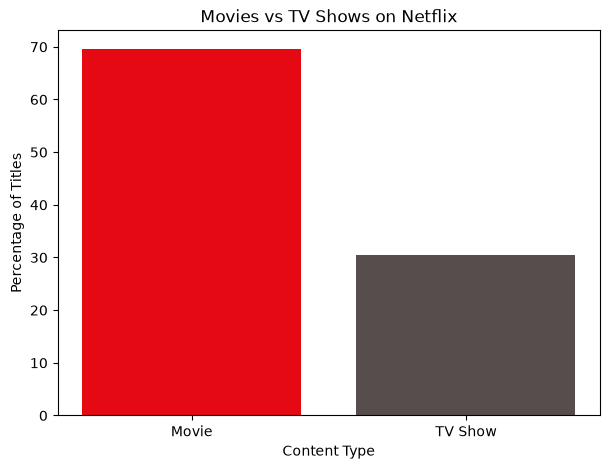

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(type_percentage.index, type_percentage.values,
         color=["#E50914", "#564D4D"])

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Percentage of Titles")

plt.show()

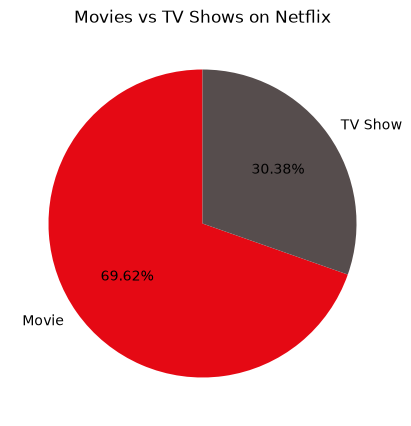

In [33]:
plt.figure(figsize=(5, 5))

plt.pie(
    type_percentage.values,
    labels=type_percentage.index,
    autopct="%.2f%%",
    startangle=90,
    colors=["#E50914", "#564D4D"]
)

plt.title("Movies vs TV Shows on Netflix")

plt.show()

### Question 1 ,Insight:

By analyzing the charts, we can interpret that Movies have a significantly higher proportion than TV Shows in the dataset. The pie chart shows that approximately **70% of the titles are Movies, while 30% are TV Shows**, indicating that Movies make up the larger share of the overall Netflix catalog represented in this dataset.

In [34]:
rating_counts = df_clean["rating"].value_counts()

rating_counts

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [35]:
df_clean[df_clean["rating"].isin(["74 min", "84 min", "66 min"])]

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
5541,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,2017-04-04,2017,74 min,NaN,Movies,NaN,NaN
5794,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,2016-09-16,2010,84 min,NaN,Movies,NaN,NaN
5813,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,2016-08-15,2015,66 min,NaN,Movies,NaN,NaN


In [36]:
mask = df_clean["rating"].str.contains("min", na=False)

df_clean.loc[mask, "duration"] = df_clean.loc[mask, "rating"]
df_clean.loc[mask, "rating"] = "Unknown"

In [37]:
df_clean.loc[mask, ["title", "rating", "duration"]]

,title,rating,duration
5541,Louis C.K. 2017,Unknown,74 min
5794,Louis C.K.: Hilarious,Unknown,84 min
5813,Louis C.K.: Live at the Comedy Store,Unknown,66 min


In [38]:
df_clean.loc[mask, "duration_value"] = pd.to_numeric(
    df_clean.loc[mask, "duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

df_clean.loc[mask, "duration_unit"] = (
    df_clean.loc[mask, "duration"].str.extract(r"([A-Za-z]+)")[0]
)

In [39]:
df_clean.loc[
    mask,
    ["title", "rating", "duration", "duration_value", "duration_unit"]
]

,title,rating,duration,duration_value,duration_unit
5541,Louis C.K. 2017,Unknown,74 min,74.0,min
5794,Louis C.K.: Hilarious,Unknown,84 min,84.0,min
5813,Louis C.K.: Live at the Comedy Store,Unknown,66 min,66.0,min


Q2 — What are the most common ratings?

In [40]:
rating_counts = df_clean["rating"].value_counts()
rating_counts

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
Unknown        7
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Which content ratings appear most frequently in the Netflix catalog?

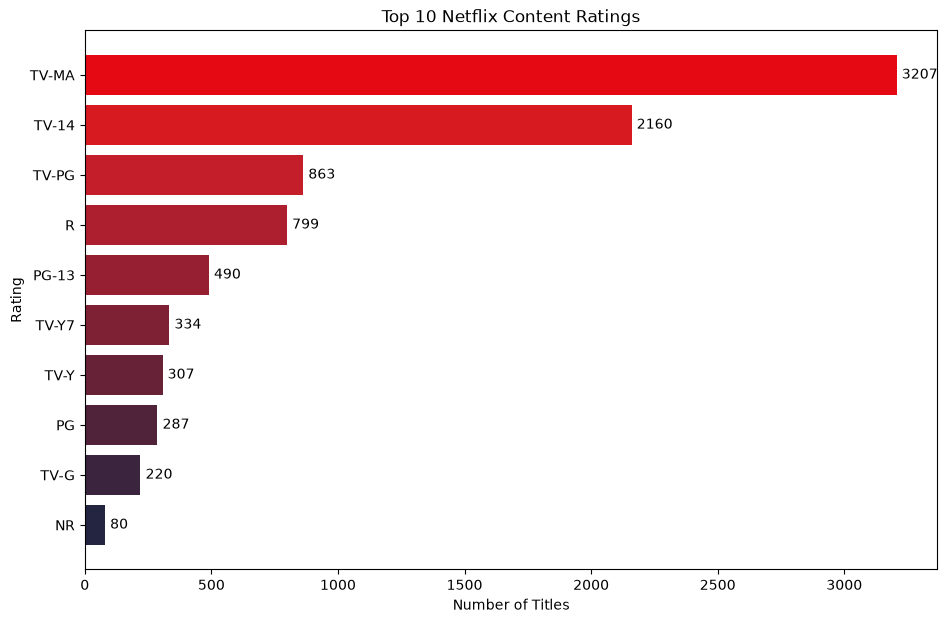

In [41]:
top_ratings = rating_counts.head(10)
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#E50914",
    "#D71920",
    "#C41E2A",
    "#AD1F2F",
    "#962032",
    "#7F2135",
    "#682238",
    "#51233B",
    "#3A243E",
    "#232541"
]

plt.barh(
    top_ratings.index,
    top_ratings.values,
    color=colors
)
#===== Add values at the end of each bar======
"""goes through each bar and gets:
- i → position of the bar
- value → actual number of titles"""
for i, value in enumerate(top_ratings.values):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.gca().invert_yaxis()

plt.show()

### Question 2 ,Insight:

By analyzing the chart, we can interpret that **TV-MA is the most common rating** in the dataset, with 3,207 titles, which is significantly higher than the other ratings. The chart also shows that **TV-MA, TV-14, and TV-PG** are the three most common ratings, indicating that these ratings represent a large portion of the content in the dataset.

Q3 — What are the most common genres?

SEPARATE THE GENRES FIRST 

In [42]:
df_clean["listed_in"].head(10)

0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
5                   TV Dramas, TV Horror, TV Mysteries
6                             Children & Family Movies
7     Dramas, Independent Movies, International Movies
8                         British TV Shows, Reality TV
9                                     Comedies, Dramas
Name: listed_in, dtype: str

In [43]:
#SPlit the Genre first
genres = df_clean["listed_in"].str.split(", ")

In [44]:
genres.head()

0                                      [Documentaries]
1    [International TV Shows, TV Dramas, TV Mysteries]
2    [Crime TV Shows, International TV Shows, TV Ac...
3                             [Docuseries, Reality TV]
4    [International TV Shows, Romantic TV Shows, TV...
Name: listed_in, dtype: object

In [45]:
#count individual genre. explode is use for this pupose so each genre gets its own count 
genre_counts = genres.explode().value_counts()

genre_counts.head(10)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

Step 1 — Select the top 10 genres

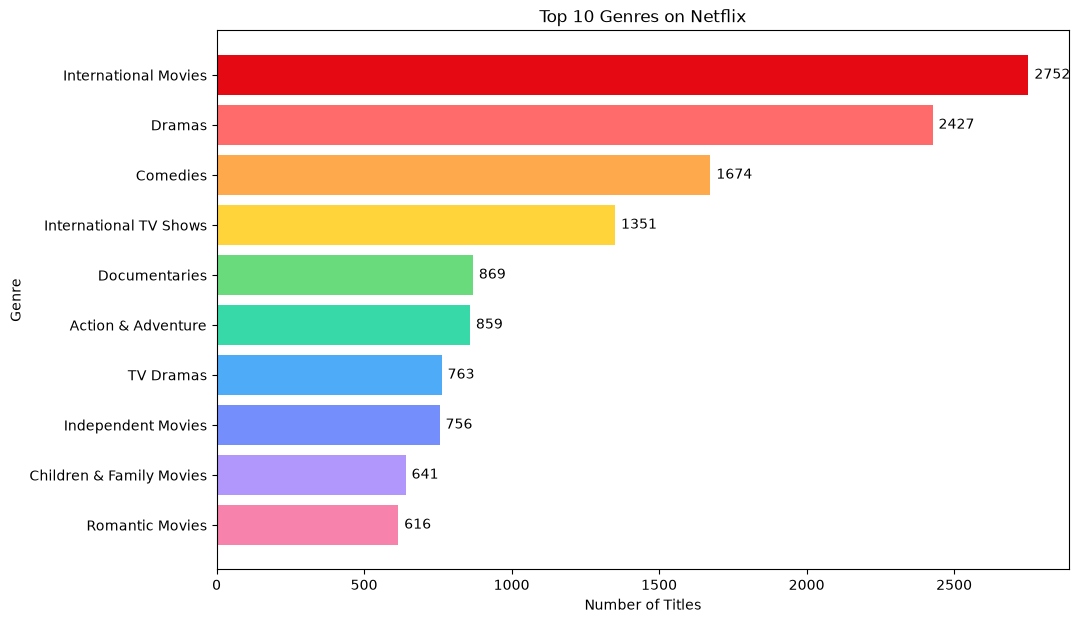

In [46]:
top_genres = genre_counts.head(10)

top_genres
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#E50914",  
    "#FF6B6B", 
    "#FFA94D",
    "#FFD43B",
    "#69DB7C",
    "#38D9A9",
    "#4DABF7",
    "#748FFC",
    "#B197FC",
    "#F783AC" 
]

plt.barh(
    top_genres.index,
    top_genres.values,
    color=colors
)

# Add numbers to the bars
for i, value in enumerate(top_genres.values):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.gca().invert_yaxis()

plt.show()

### Question 3 , Insight:

By analyzing the data and observing the chart, we can interpret that **International Movies are the most common genre**, with 2,752 titles, which is significantly higher than the other genres shown. The chart also shows that **International Movies, Dramas, Comedies, and International TV Shows** are the four most common genres in the dataset.

Q4 — Which countries have the most Netflix titles?

The country column is similar to listed_in: a title can belong to multiple countries.
so perform same operations as listed in first split then explode function 


In [47]:
countries = df_clean["country"].str.split(", ")
countries.head()
country_counts = countries.explode().value_counts()

country_counts.head(10)

country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64

Clean the country ranking for visualization

-As we can see  831 countries are unknown 

-Since Unknown represents missing country information, remove it only from this country-specific analysis. We don't need to change df_clean.

In [48]:
country_counts_known = country_counts.drop("Unknown")

top_countries = country_counts_known.head(10)

top_countries

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

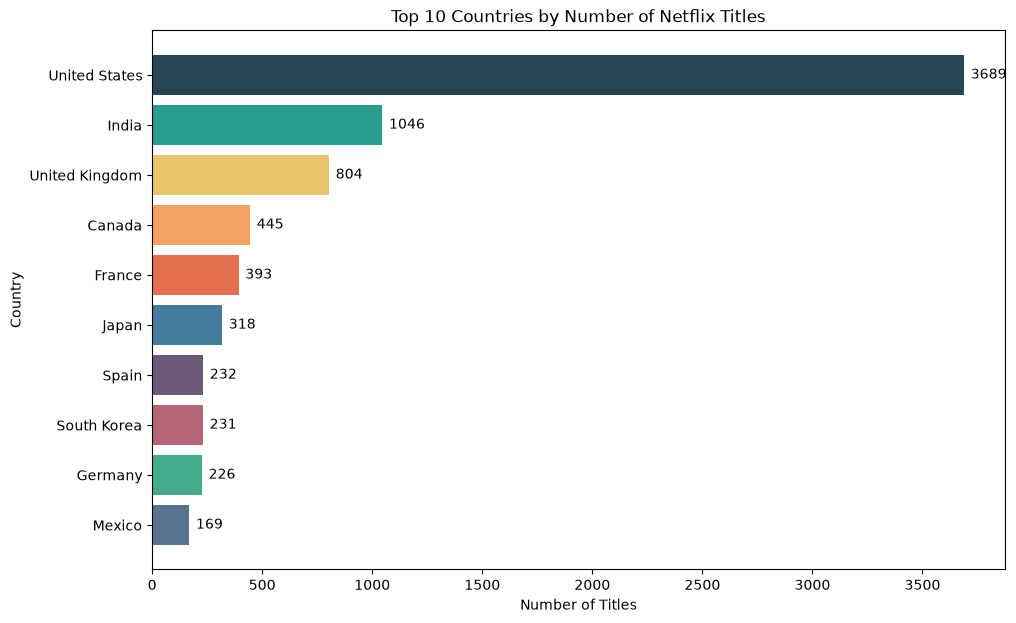

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#264653",
    "#2A9D8F",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#457B9D",
    "#6D597A",
    "#B56576",
    "#43AA8B",
    "#577590"
]

plt.barh(
    top_countries.index,
    top_countries.values,
    color=colors
)

for i, value in enumerate(top_countries.values):
    plt.text(
        value + 30,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.show()

###  Question 4 ,Insight:

By analyzing the data and observing the chart, we can interpret that the **United States is the country associated with the highest number of titles**, with 3,689 titles, which is significantly higher than the other countries shown. However, this does not mean that all of these titles were produced solely by the United States, because a single title can be associated with multiple countries. Therefore, the results represent the number of titles associated with each country rather than titles produced exclusively by that country.

Q5 — Which release years have the most titles?

In [50]:
release_year_counts = df_clean["release_year"].value_counts().sort_index()

release_year_counts.head()
#find top 10 release years
top_release_years = df_clean["release_year"].value_counts().head(10).sort_index()

top_release_years

release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

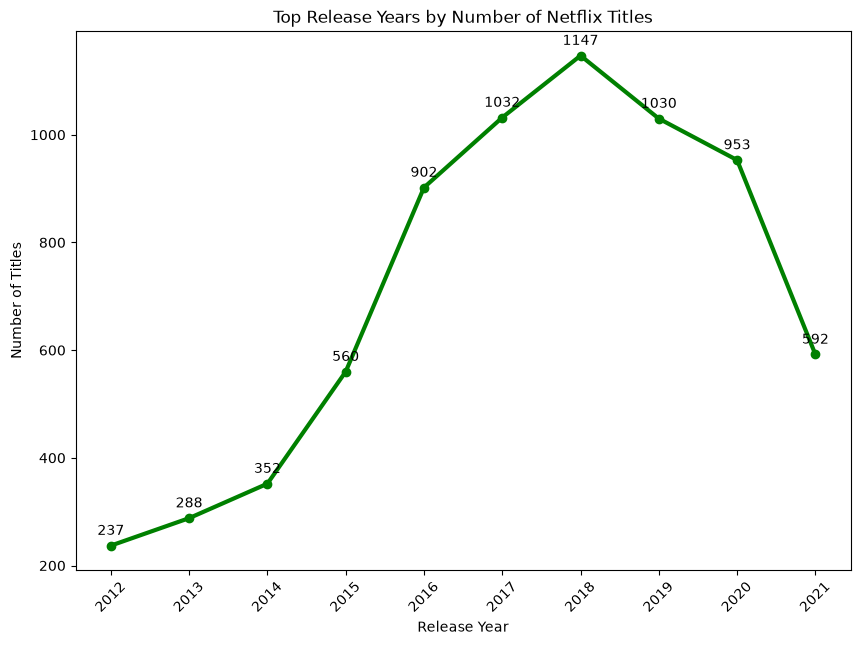

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.plot(
    top_release_years.index,
    top_release_years.values,
    marker="o",
    linewidth=3,
    color="green"
)

for year, value in zip(top_release_years.index, top_release_years.values):
    plt.text(
        year,
        value + 20,
        str(value),
        ha="center"
    )

plt.title("Top Release Years by Number of Netflix Titles")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.xticks(top_release_years.index, rotation=45)

plt.show()

### Question 5, Insight:

By analyzing the line chart, we can interpret that the chart represents the **top 10 release years with the highest number of titles** in the dataset. The number of titles increases significantly from 2012 to 2018, reaching the highest point in **2018 with 1,147 titles**. After 2018, the number of titles gradually decreases, reaching 592 titles in 2021.

Q6 — How are movie durations distributed?

for this we will only use movies because our drama type contains seasons not numerical time duration 

In [52]:
movies = df_clean[df_clean["type"] == "Movie"]
movies["duration_value"].describe()

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

As movies durations are of very close and of small intervals it becomes difficult to read 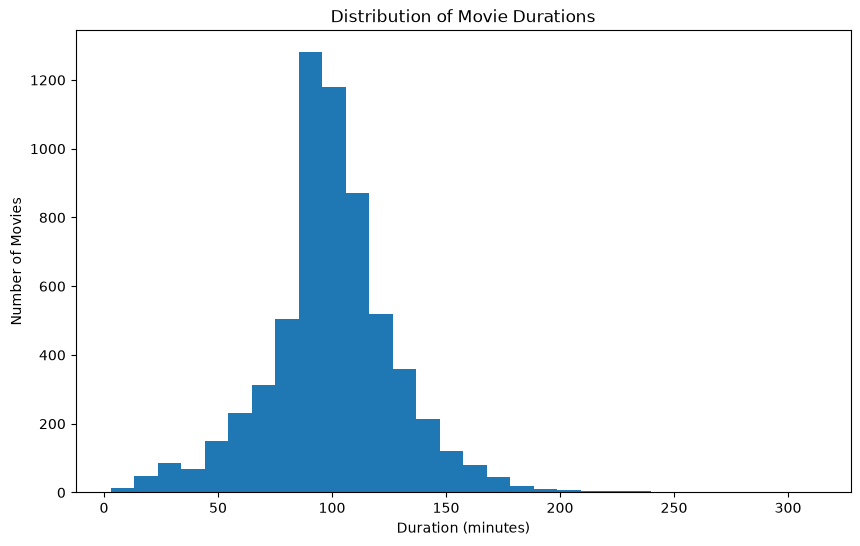 

as you can see from here , so better appraoch is to divide time duration into group intervals  so it becomes easy to understand and interpret the insight 

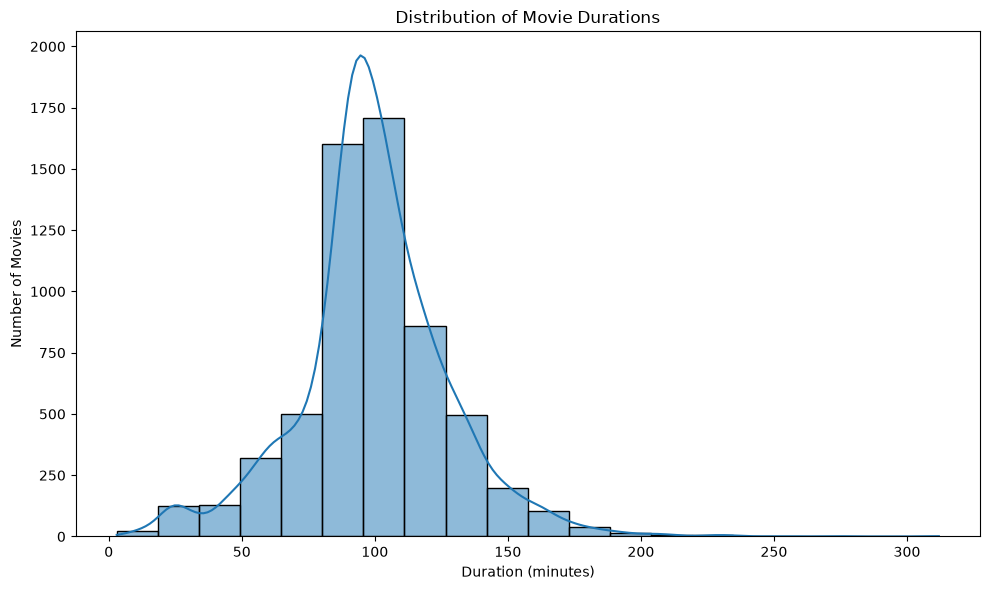

In [53]:
movies = df_clean[
    (df_clean["type"] == "Movie") &
    (df_clean["duration_unit"] == "min")
]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=movies,
    x="duration_value",
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

### Question 6 — Insight: Movie Duration Distribution

By analyzing the movie duration data, we can observe that the **90–119 minute range is the most common duration category, containing 3,092 movie titles**. The 60–89 minute range follows with 1,383 titles, while the 120–149 minute range contains 936 titles. The number of movies decreases across the longer duration categories, indicating that very long movies are less common in this dataset.Overall from 90-119 range contains 3092 movies titles.

This analysis focuses only on Movies because TV Shows are represented by the number of seasons rather than duration in minutes. The histogram helps visualize the overall distribution of movie durations, while the grouped analysis provides exact counts for each duration category.

Q7 — Has the Movies vs TV Shows balance changed over time?

pd.crosstab() is useful because it counts combinations of two categorical variables.

In [54]:
type_by_year = pd.crosstab(
    df_clean["release_year"],
    df_clean["type"]
)

type_by_year.tail(10)

type,Movie,TV Show
release_year,,
2012,173,64
2013,225,63
2014,264,88
2015,398,162
2016,658,244
2017,767,265
2018,767,380
2019,633,397
2020,517,436


In [55]:
recent_type_by_year = type_by_year.loc[2000:2021]

recent_type_by_year

type,Movie,TV Show
release_year,,
2000,33,4
2001,40,5
2002,44,7
2003,51,10
2004,55,9
2005,67,13
2006,82,14
2007,74,14
2008,113,23


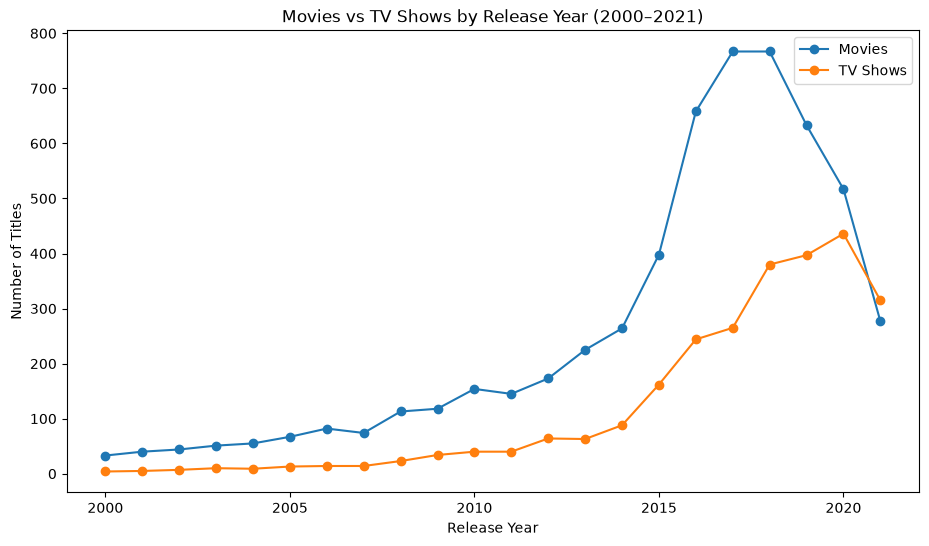

In [56]:
recent_type_by_year = pd.crosstab(
    df_clean["release_year"],
    df_clean["type"]
).loc[2000:2021]

plt.figure(figsize=(11, 6))

plt.plot(
    recent_type_by_year.index,
    recent_type_by_year["Movie"],
    marker="o",
    label="Movies"
)

plt.plot(
    recent_type_by_year.index,
    recent_type_by_year["TV Show"],
    marker="o",
    label="TV Shows"
)

plt.title("Movies vs TV Shows by Release Year (2000–2021)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.legend()

plt.show()

### Question 7,Insight:

After analyzing the chart, we can observe that both Movies and TV Shows generally show an increasing trend in the number of titles from 2000 onward. However, their trends differ in the later years. **Movies reach their highest number around 2017–2018 and then gradually decrease**, while **TV Shows continue increasing after 2018 and reach their highest point around 2020 before decreasing in 2021**. This shows that the distribution of Movies and TV Shows varies across different release years.

Q8 — Do Movies and TV Shows have different rating patterns?

In [57]:
rating_by_type = pd.crosstab(
    df_clean["rating"],
    df_clean["type"]
)

rating_by_type

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,733
TV-G,126,94
TV-MA,2062,1145


In [58]:
rating_percentage = rating_by_type.div(
    rating_by_type.sum(axis=0),
    axis=1
) * 100

rating_percentage = rating_percentage.round(2)

rating_percentage

type,Movie,TV Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.19
PG,4.68,0.00
PG-13,7.99,0.00
R,13.00,0.07
TV-14,23.28,27.39
TV-G,2.06,3.51
TV-MA,33.63,42.79


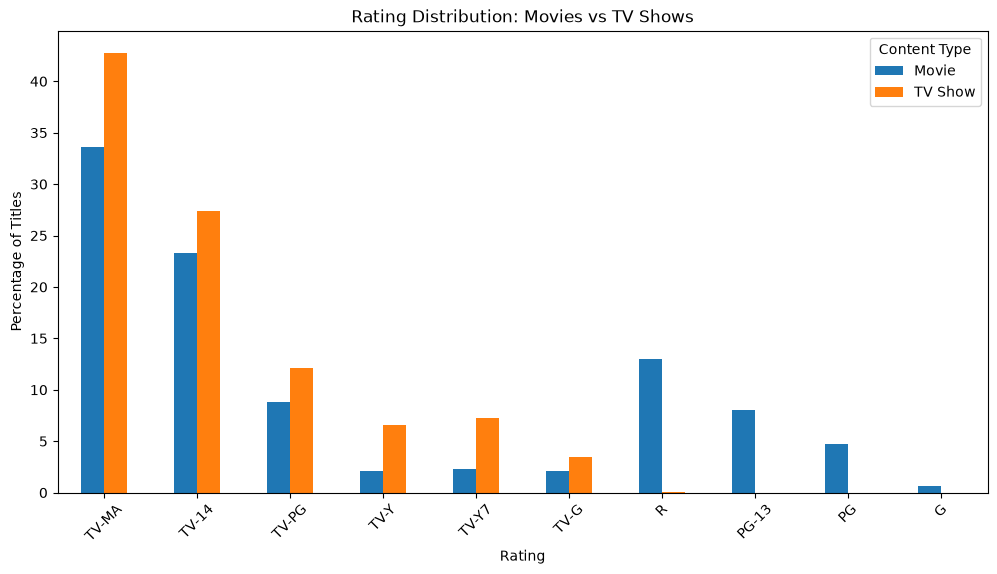

In [59]:
main_ratings = [
    "TV-MA",
    "TV-14",
    "TV-PG",
    "TV-Y",
    "TV-Y7",
    "TV-G",
    "R",
    "PG-13",
    "PG",
    "G"
]

rating_comparison = rating_percentage.loc[main_ratings]
rating_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Rating Distribution: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Percentage of Titles")
plt.xticks(rotation=45)

plt.legend(title="Content Type")

plt.show()

###Question 8, Insight:

After analyzing the chart, we can interpret that **TV-MA has the highest proportion among both Movies and TV Shows**. However, when comparing the two content types, **TV Shows have a higher proportion of TV-MA titles than Movies**. This indicates that TV-MA content represents a larger share of the TV Show catalog compared with its share of the Movie catalog.

Q9 — Do major countries differ in Movies vs TV Shows?

same operation as a country title contains multiple countries in its rows


Because one title can have multiple countries, explode() creates multiple rows with the same original index.
So when pd.crosstab() tries to align the two Series, a duplicate reindex error occurs so uses reset_indes after explode 

In [60]:
country_data = df_clean.assign(
    country=df_clean["country"].str.split(", ")
).explode("country").reset_index(drop=True)

not deleting anythinng just removing or filtering unknown countries from this particular analysis 

In [61]:
country_data = country_data[
    country_data["country"].notna() &
    (country_data["country"] != "") &
    (country_data["country"] != "Unknown")
]

In [62]:
country_type = pd.crosstab(
    country_data["country"],
    country_data["type"]
)

country_type.head(20)

type,Movie,TV Show
country,,
Afghanistan,1,0
Albania,1,0
Algeria,3,0
Angola,1,0
Argentina,71,20
Armenia,1,0
Australia,94,66
Austria,11,1
Azerbaijan,0,1


In [63]:
top_country_names = country_counts_known.head(10).index

In [64]:
top_country_type = country_type.loc[top_country_names]

top_country_type

type,Movie,TV Show
country,,
United States,2751,938
India,962,84
United Kingdom,532,272
Canada,319,126
France,303,90
Japan,119,199
Spain,171,61
South Korea,61,170
Germany,182,44


In [65]:
country_type_percentage = (
    top_country_type
    .div(top_country_type.sum(axis=1), axis=0)
    * 100
).round(2)

country_type_percentage

type,Movie,TV Show
country,,
United States,74.57,25.43
India,91.97,8.03
United Kingdom,66.17,33.83
Canada,71.69,28.31
France,77.10,22.90
Japan,37.42,62.58
Spain,73.71,26.29
South Korea,26.41,73.59
Germany,80.53,19.47


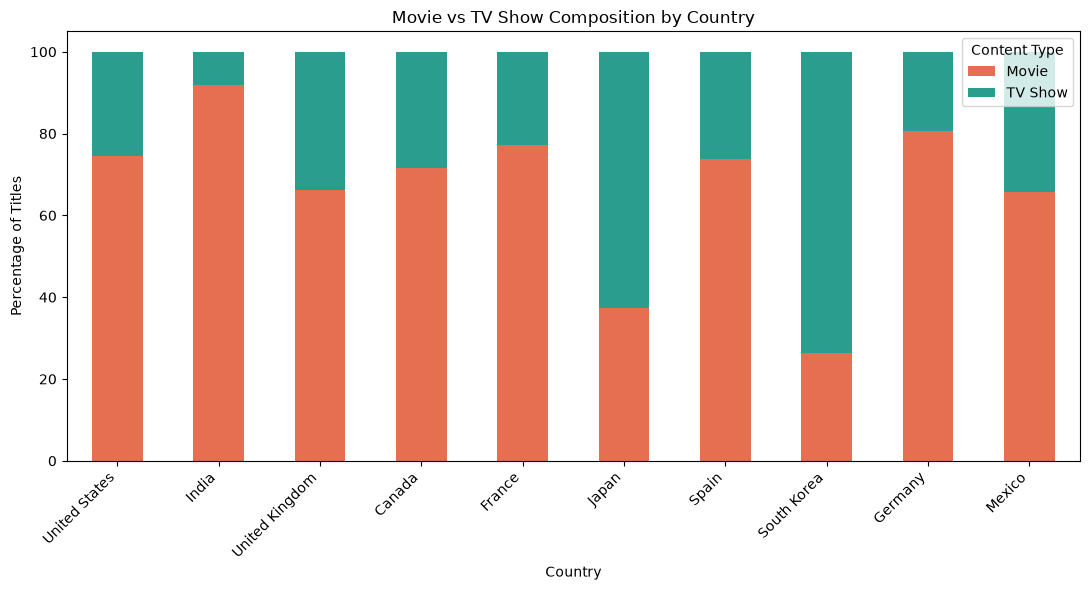

In [66]:
import matplotlib.pyplot as plt

country_type_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#E76F51", "#2A9D8F"]
)

plt.title("Movie vs TV Show Composition by Country")
plt.xlabel("Country")
plt.ylabel("Percentage of Titles")

plt.xticks(rotation=45, ha="right")

plt.legend(title="Content Type")

plt.tight_layout()

plt.show()

### Question 9,Insight:

By analyzing the chart, we can observe that **India has a particularly high proportion of Movie titles**, while countries such as Japan and South Korea have a considerably larger proportion of TV Shows. Overall, the major countries shown in the analysis differ in their distribution of Movies and TV Shows, although some countries have relatively similar Movie proportions.

However, this analysis is based only on titles with known country information, as the `Unknown` country values were excluded. Therefore, the results should be interpreted as a comparison of the **selected countries represented in the dataset**, rather than a complete representation of all countries in the Netflix catalog.

Q10 — Is the Netflix catalog mainly recent or older content?

In [67]:
release_bins = [0, 2000, 2010, 2015, 2020, 2022]

release_labels = [
    "Before 2000",
    "2000–2009",
    "2010–2014",
    "2015–2019",
    "2020–2021"
]

df_clean["release_period"] = pd.cut(
    df_clean["release_year"],
    bins=release_bins,
    labels=release_labels,
    right=False
)
release_period_counts = df_clean["release_period"].value_counts().sort_index()

release_period_counts

release_period
Before 2000     525
2000–2009       810
2010–2014      1256
2015–2019      4671
2020–2021      1545
Name: count, dtype: int64

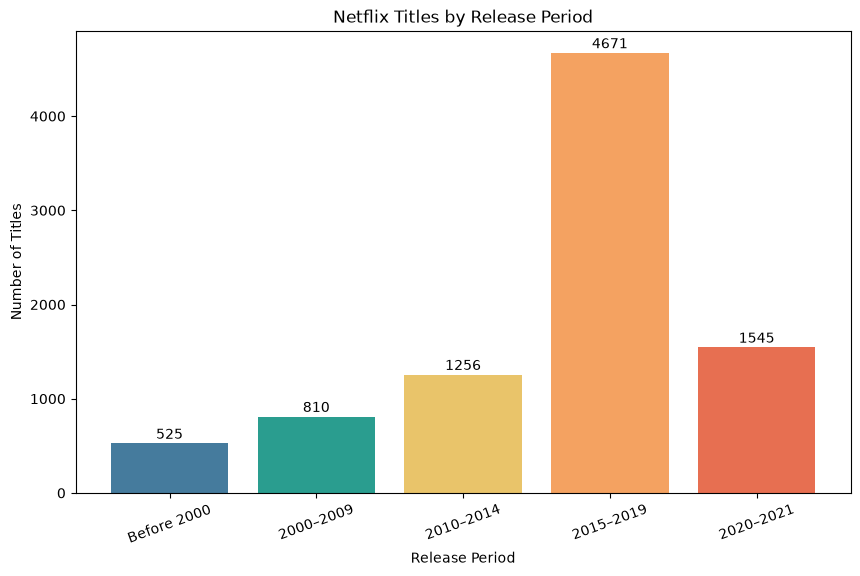

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    release_period_counts.index,
    release_period_counts.values,
    color=[
        "#457B9D",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51"
    ]
)

for i, value in enumerate(release_period_counts.values):
    plt.text(
        i,
        value + 50,
        str(value),
        ha="center"
    )

plt.title("Netflix Titles by Release Period")
plt.xlabel("Release Period")
plt.ylabel("Number of Titles")

plt.xticks(rotation=20)

plt.show()

###Question 10, Insight:

After analyzing the chart, we can interpret that a large portion of the Netflix catalog represented in the dataset consists of relatively recent content. The **2015–2019 release period has the highest number of titles, with 4,671 titles**, which is significantly higher than the other release periods. This indicates that the dataset is largely concentrated around titles released during the more recent years.

Q11 — How old were titles when they were added to Netflix?

In [69]:
#===claculate the age of content when it was added to Netflix======
df_clean["age_when_added"] = (
    df_clean["date_added"].dt.year
    - df_clean["release_year"]
)

In [70]:
df_clean["age_when_added"].describe()

count    8709.000000
mean        4.690894
std         8.792208
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: age_when_added, dtype: float64

In [71]:
df_clean[
    df_clean["age_when_added"] < 0
][
    ["title", "release_year", "date_added", "age_when_added"]
]

,title,release_year,date_added,age_when_added
1551,Hilda,2021,2020-12-14,-1.0
1696,Polly Pocket,2021,2020-11-15,-1.0
2920,Love Is Blind,2021,2020-02-13,-1.0
3168,Fuller House,2020,2019-12-06,-1.0
3287,Maradona in Mexico,2020,2019-11-13,-1.0
3369,BoJack Horseman,2020,2019-10-25,-1.0
3433,The Hook Up Plan,2020,2019-10-11,-1.0
4844,Unbreakable Kimmy Schmidt,2019,2018-05-30,-1.0
4845,Arrested Development,2019,2018-05-29,-1.0
5394,Hans Teeuwen: Real Rancour,2018,2017-07-01,-1.0


In [72]:
df_clean["age_when_added_clean"] = df_clean["age_when_added"].where(
    df_clean["age_when_added"] >= 0
)

In [73]:
df_clean["age_when_added_clean"].describe()

count    8695.000000
mean        4.700403
std         8.796060
min         0.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: age_when_added_clean, dtype: float64

In [74]:
age_bins = [-1, 0, 1, 3, 6, 11, float("inf")]

age_labels = [
    "Same year",
    "1 year",
    "2–3 years",
    "4–6 years",
    "7–11 years",
    "12+ years"
]

df_clean["addition_age_group"] = pd.cut(
    df_clean["age_when_added_clean"],
    bins=age_bins,
    labels=age_labels
)
age_group_counts = (
    df_clean["addition_age_group"]
    .value_counts()
    .sort_index()
)

age_group_counts

addition_age_group
Same year     3222
1 year        1559
2–3 years     1191
4–6 years      865
7–11 years     795
12+ years     1063
Name: count, dtype: int64

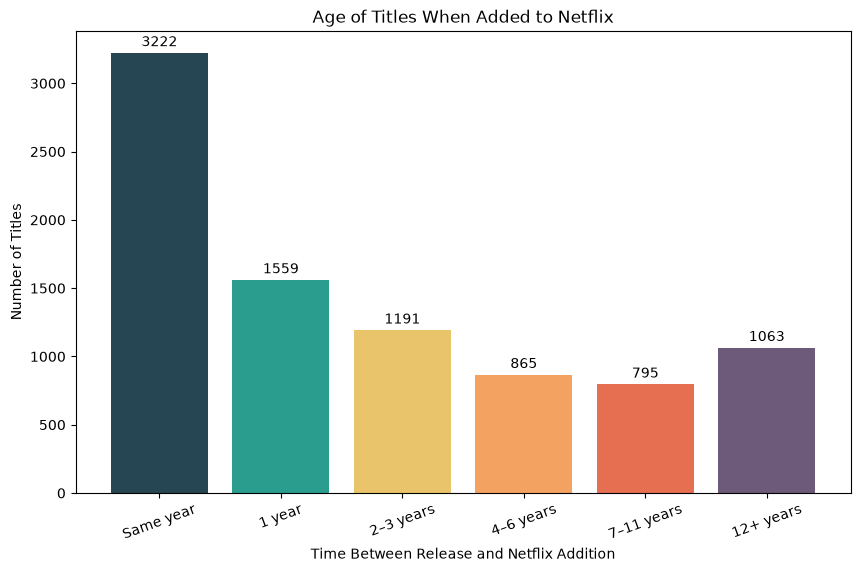

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    age_group_counts.index,
    age_group_counts.values,
    color=[
        "#264653",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51",
        "#6D597A"
    ]
)

for i, value in enumerate(age_group_counts.values):
    plt.text(
        i,
        value + 50,
        str(value),
        ha="center"
    )

plt.title("Age of Titles When Added to Netflix")
plt.xlabel("Time Between Release and Netflix Addition")
plt.ylabel("Number of Titles")

plt.xticks(rotation=20)

plt.show()

### Question 11,Insight:

By analyzing the chart, we can interpret that **titles added to Netflix in the same year as their release have the highest count**, with 3,222 titles. This is considerably higher than the other age groups. However, this analysis has a limitation because some titles in the dataset produced negative age values, meaning their recorded Netflix addition date was earlier than their recorded release year. These values were excluded from this specific age analysis. Therefore, based on the valid age values analyzed, the **same-year category represents the largest group of titles**.

Q12 — Which directors have the most titles on Netflix?

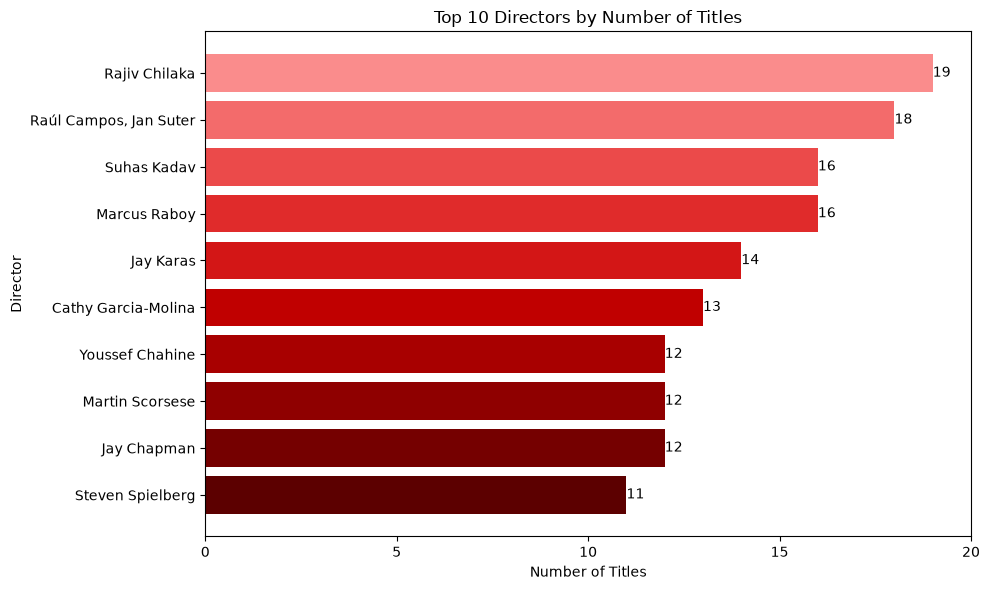

In [76]:
director_counts = (
    df_clean[df_clean["director"] != "Unknown"]["director"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    director_counts.index[::-1],
    director_counts.values[::-1],
   color = [
    "#5C0000",
    "#750000",
    "#8F0000",
    "#A80000",
    "#C00000",
    "#D31616",
    "#E02B2B",
    "#EB4A4A",
    "#F36B6B",
    "#FA8C8C"
]
)

for i, value in enumerate(director_counts.values[::-1]):
    plt.text(
        value + 0,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Directors by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Director")
plt.xticks(range(0, 21, 5))
plt.tight_layout()
plt.show()

### Question 12, Insight:

After analyzing the chart, we can interpret that Rajiv Chilaka has the highest number of titles among the directors shown, with 19 titles, followed by **Raúl Campos and Jan Suter with 18 titles**. However, this analysis excludes titles where the director information was recorded as Unknown. Therefore, based on the available director information in the dataset, Rajiv Chilaka has the highest number of titles among the directors represented in this analysis.

Q13 — Which actors appear most frequently?

In [77]:
cast_data = df_clean.assign(
    actor=df_clean["cast"].str.split(", ")
).explode("actor").reset_index(drop=True)
cast_data = cast_data[
    cast_data["actor"].notna() &
    (cast_data["actor"] != "Unknown") &
    (cast_data["actor"] != "")
]

In [ ]:
actor_counts = (
    cast_data["actor"]
    .value_counts()
    .head(10)
)

actor_counts

actor
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64

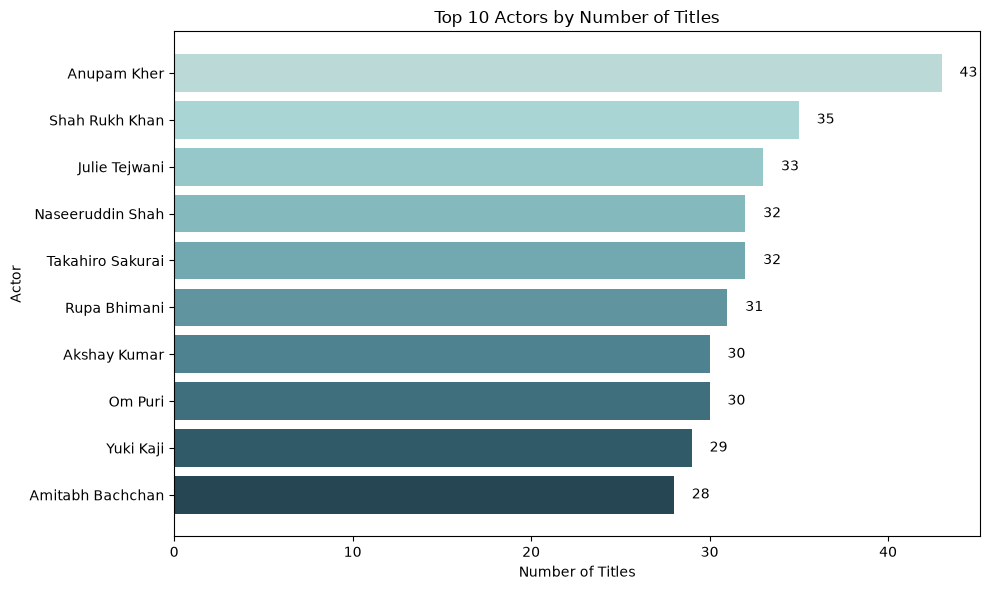

In [ ]:
colors = [
    "#264653",
    "#315A68",
    "#3F6F7D",
    "#4F8290",
    "#6095A0",
    "#72A8AF",
    "#84B9BD",
    "#96C8C9",
    "#A9D6D4",
    "#BBD9D7"
]

plt.figure(figsize=(10, 6))

plt.barh(
    actor_counts.index[::-1],
    actor_counts.values[::-1],
    color=colors
)

for i, value in enumerate(actor_counts.values[::-1]):
    plt.text(
        value + 1,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Actors by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Actor")

plt.tight_layout()
plt.show()

### Question 13 , Insight:

After analyzing the chart, we can interpret that **Anupam Kher has the highest number of titles among the actors shown, with 43 titles**, followed by **Shah Rukh Khan with 35 titles**. However, this analysis excludes titles where the actor information was recorded as `Unknown`. Therefore, based on the available actor information, **Anupam Kher has the highest number of titles among the actors represented in this analysis**.

Q14 — Which genres are most common within Movies vs TV Shows?

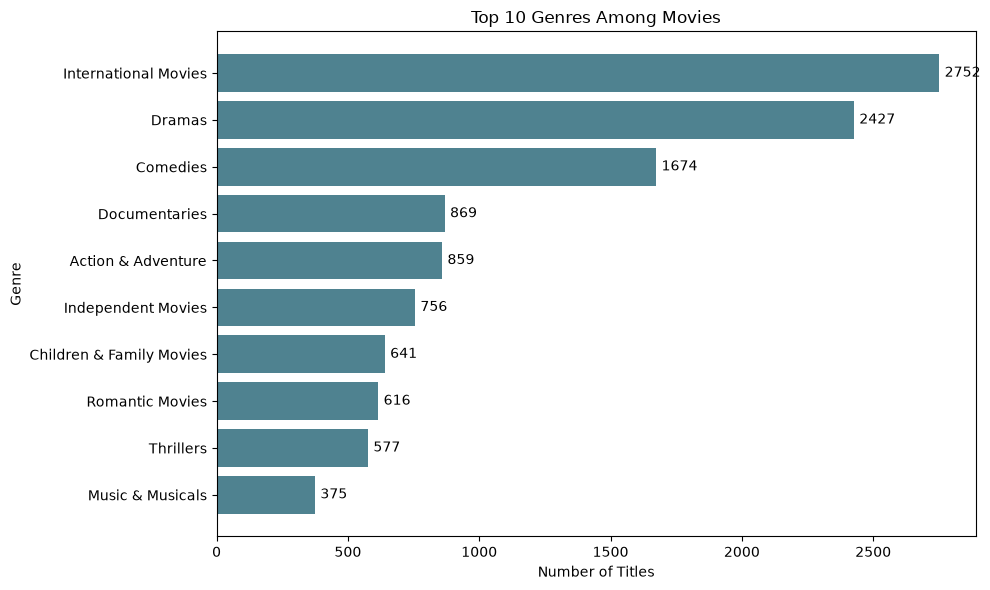

In [ ]:
genre_data = df_clean.assign(
    genre=df_clean["listed_in"].str.split(", ")
).explode("genre")

movie_genres = (
    genre_data[genre_data["type"] == "Movie"]["genre"]
    .value_counts()
    .head(10)
)

tv_genres = (
    genre_data[genre_data["type"] == "TV Show"]["genre"]
    .value_counts()
    .head(10)
)
plt.figure(figsize=(10, 6))

plt.barh(
    movie_genres.index[::-1],
    movie_genres.values[::-1],
    color="#4F8290"
)

for i, value in enumerate(movie_genres.values[::-1]):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres Among Movies")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### question 14, part A, Insight:

After analyzing the chart, we can interpret that **International Movies is the most common genre among Movies**, with 2,752 titles, followed by **Dramas with 2,427 titles**. This shows that these two genres have the highest number of titles among the movie genres represented in the analysis.

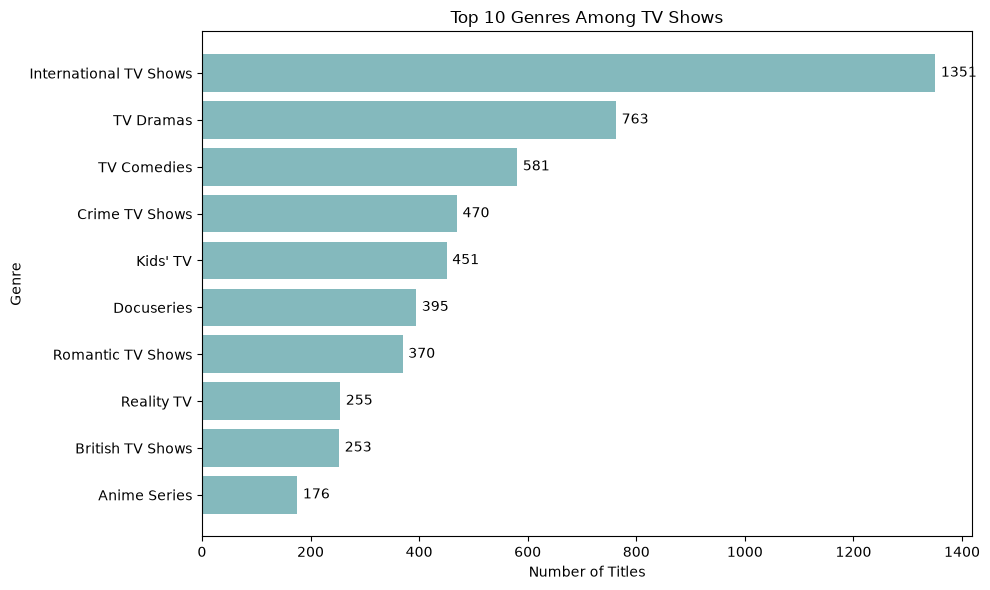

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    tv_genres.index[::-1],
    tv_genres.values[::-1],
    color="#84B9BD"
)

for i, value in enumerate(tv_genres.values[::-1]):
    plt.text(
        value + 10,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres Among TV Shows")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### question 14,part B, Insight:

After analyzing the chart, we can interpret that **International TV Shows are the most common genre among TV Shows**, with 1,351 titles, followed by **TV Dramas with 763 titles**. TV Comedies are the third most common genre, with 581 titles. Overall, International TV Shows have a considerably higher number of titles than the other TV Show genres represented in the analysis.

END 

## 7. Key Findings

The exploratory analysis identified several notable patterns in the Netflix catalog:

- Movies represent the larger share of the dataset, accounting for approximately **69.62%** of titles.
- **TV-MA** is the most common content rating.
- **International Movies** is the most common genre category overall.
- The **United States** is associated with the highest number of titles among the countries analyzed.
- **2018** has the highest number of titles among the release years analyzed.
- Most movies fall within the **90–119 minute** duration range.
- Titles released and added to Netflix in the **same year** form the largest age group.
- **Rajiv Chilaka** has the highest number of titles among the available director data.
- **Anupam Kher** has the highest number of titles among the available actor data.
- Movies generally dominate the catalog, although TV Shows show a stronger presence in more recent release years.

## 8. Limitations

This analysis has several limitations that should be considered when interpreting the results:

- The dataset represents a **catalog snapshot** and does not represent the current Netflix catalog.
- Several records contain missing information, particularly for directors, cast, and countries.
- Some titles are associated with multiple countries and genres, so counts can exceed the total number of titles.
- The `release_year` represents the original release year of the title and should not be interpreted as the year it was added to Netflix.
- The analysis of age when added to Netflix contains a small number of inconsistent negative values, which were excluded from that specific analysis without removing the original records.
- Country, director, and actor analyses are based only on the information available in the dataset.

# Final Conclusion

This exploratory data analysis provided an overall understanding of the Netflix catalog represented in the dataset. After cleaning the data and handling missing and inconsistent values, different aspects of the catalog were analyzed, including content types, ratings, genres, countries, release years, durations, addition patterns, directors, and actors.

The analysis shows that **Movies represent the larger share of the dataset, accounting for approximately 69.62% of the titles, while TV Shows account for 30.38%**. TV-MA was the most common rating, while International Movies was the most common genre overall. The United States was associated with the highest number of titles among the countries analyzed. The release-year analysis showed that the number of titles was particularly high in recent years, with 2018 having the highest number of titles among the years analyzed. Most movies had a duration between **90 and 119 minutes**, while titles added in the same year as their release formed the largest age group.

The analysis also identified Rajiv Chilaka as the director with the highest number of titles among the available director data and Anupam Kher as the actor with the highest number of titles among the available actor data.

Overall, the analysis demonstrates how data cleaning, exploratory analysis, and visualization can be used to identify meaningful patterns while also considering the limitations and structure of the dataset.